# Occupancy, gains, setpoints and DHW

Use explicit operational assumptions to represent contrasting buildings and isolate their effects.

This is an executable lesson about representing building-stock diversity with EPSM Core. All dimensions are metric. The materials, use patterns and stock weights are explicit demonstration assumptions, not calibrated national statistics. Read each explanation before changing the code.

**How to use:** select the **EPSM Core Demo** kernel and Run All from a fresh kernel. Each notebook is independent; generated files go under `output/demo/`. Setup instructions and the complete learning path are in [the demo guide](../README.md).

**Prerequisites:** local EPW, EnergyPlus 24.2.

## Understanding the API in this lesson

`UseSpec` supplies prescribed people, equipment, lighting, setpoints and DHW. Density is people per conditioned m²; activity is W/person; equipment and lighting intensities are W/m². Fraction schedules multiply their respective intensities over the repeated day.

Prescribed gains per area can be read as `people_density × activity × occupancy_fraction + equipment_intensity × equipment_fraction + lighting_intensity × lighting_fraction`. Annual DHW intensity is in kWh/(m²·year), a different quantity. These inputs occupy the operations stage of the workflow; the simulation determines how the building responds to them.

Reference: [From observed geometry to an accepted energy comparison](../../docs/figures/workflow.svg). This linked documentation illustration is separate from the outputs computed below.

### Before the first code cell

The setup cell finds the repository, imports the package and plotting tools, and creates a fresh `OUT` directory. `building()` and `geometry()` are **demo input factories**; `table()`, `plans()`, `bars()` and `preview()` are **presentation helpers**, not public `epsm_core` entry points. In particular, `preview()` already displays its output and returns no handle, avoiding duplicate widget display. The public specification and simulation calls remain visible in the lesson cells. Run the setup once per fresh kernel, then follow the cells in order.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/epsm_core").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import json
from dataclasses import asdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from epsm_core import *
from demo.support.common import (building, geometry, epw, engine, workspace, table,
                                 plans, preview, bars, weather_frame, result_frame, result_plots)
from epsm_core.inspection import geometry_scene
OUT = workspace(Path.cwd().name)


### Prescribed schedules scale input intensities

The gain curves below multiply occupancy, equipment and lighting by their own profiles before summing. Occupant gains also use activity in watts per person. Heating setpoints are temperatures, not fractions; DHW annual intensity has separate normalization. Repeating one daily profile is an explicit simplification, not a national calendar model.

The following original diagram is conceptual API guidance; the later charts and tables report the computed example values.

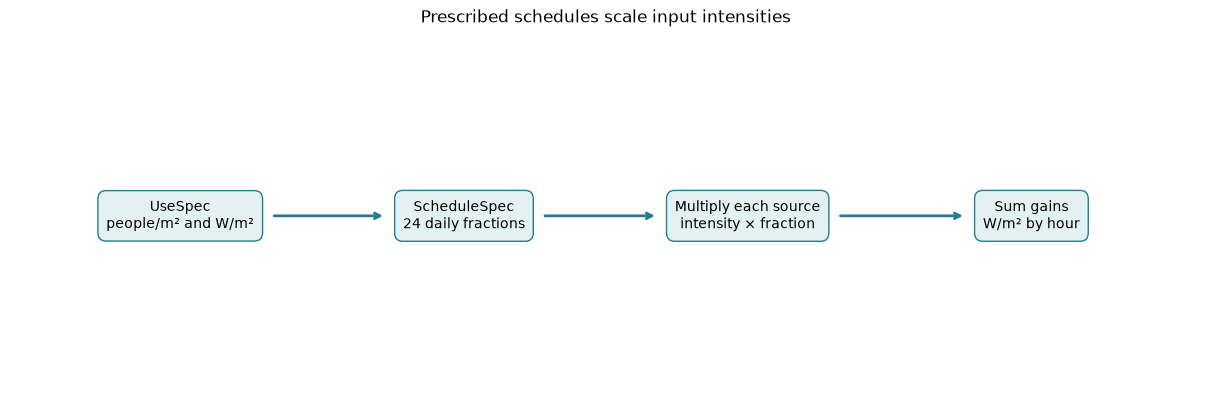

In [2]:
from demo.support.common import flow
flow(['UseSpec\npeople/m² and W/m²', 'ScheduleSpec\n24 daily fractions', 'Multiply each source\nintensity × fraction', 'Sum gains\nW/m² by hour'], 'Prescribed schedules scale input intensities', figsize=(12, 4))

## Build contrasting use profiles

Occupant density is per conditioned floor area. Fraction schedules modulate gains, while annual DHW intensity controls an energy total.

### Read the code and output

“Residential” and “office-like” are labels for the explicit assumptions shown here, not a lookup into a national use catalogue. The daytime profile repeats every day. Inspect density, gain intensity and DHW separately before reusing this example for an observed building with another operating pattern.

,use,people_per_m2,equipment_W_m2,DHW_kWh_m2_year
0,residential,0.017,1.68,21.0
1,office-like,0.050,6.00,5.0


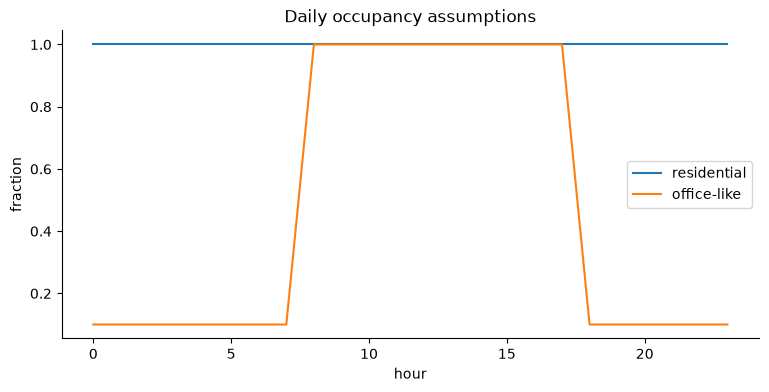

In [3]:
b = building()
daytime = ScheduleSpec(values=tuple(1 if 8<=h<18 else .1 for h in range(24)))
residential = b.use.updated(occupancy_category="residential", lighting_gain_w_m2=2)
office = UseSpec(occupancy_category="non_residential",heating_setpoint=ScheduleSpec.constant(21),occupant_density_per_m2=.05,equipment_gain_w_m2=6,lighting_gain_w_m2=5,dhw_kwh_m2_year=5,occupancy_fraction=daytime,equipment_fraction=daytime,lighting_fraction=daytime)
uses={"residential":residential,"office-like":office}
table([{ "use":name,"people_per_m2":u.occupant_density_per_m2,"equipment_W_m2":u.equipment_gain_w_m2,"DHW_kWh_m2_year":u.dhw_kwh_m2_year} for name,u in uses.items()])
fig, ax = plt.subplots(figsize=(9, 4))
pd.DataFrame({name:u.occupancy_fraction.values for name,u in uses.items()}).plot(ax=ax, xlabel="hour",ylabel="fraction",title="Daily occupancy assumptions"); plt.show(); plt.close(fig)

## Compare prescribed internal gains

The plotted people gains use activity per person and the supplied fraction. These are prescribed inputs, not measured occupancy.

### Read the code and output

The gain curve adds people, equipment and lighting powers per area; it does not include heating-system delivery. The prescribed total is not an indoor air-temperature prediction because storage, transmission and ventilation also affect the zone balance. Its purpose is to verify the intended operation before running the engine.

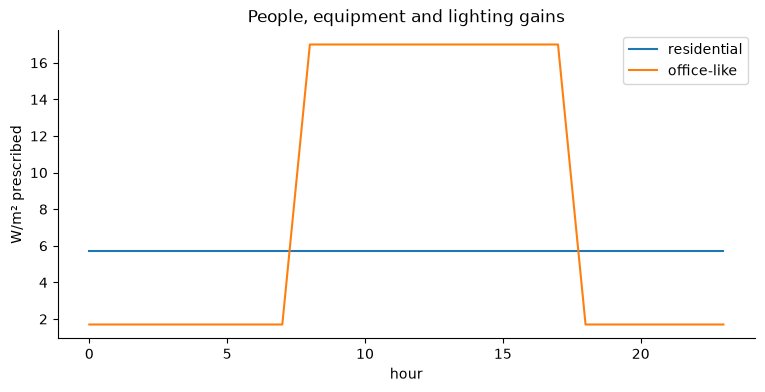

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
for name,u in uses.items():
    gains = np.array(u.occupancy_fraction.values)*u.occupant_density_per_m2*u.occupant_activity_w + np.array(u.equipment_fraction.values)*u.equipment_gain_w_m2 + np.array(u.lighting_fraction.values)*u.lighting_gain_w_m2
    plt.plot(gains,label=name)
plt.legend(); plt.xlabel("hour"); plt.ylabel("W/m² prescribed"); plt.title("People, equipment and lighting gains"); plt.show(); plt.close(fig)

## Run matched operations

Changing use can change heating and DHW in opposite directions. Keep the geometry and weather identical to isolate operations.

### Read the code and output

DHW should reconcile with intensity times conditioned area to within the stated tolerance. Heating also changes as internal gains change, so lower heating alone is not proof of lower total building energy. This comparison deliberately changes a use package, including DHW, and should be labelled that way.

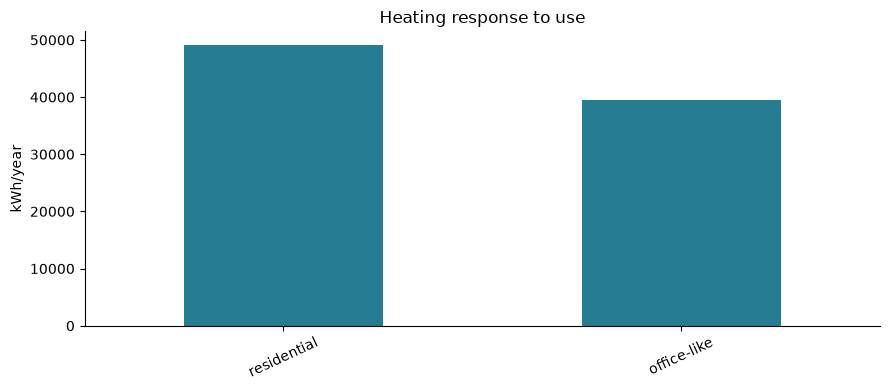

In [5]:
results={name:EnergyPlusRunner(engine()).run(b.updated(use=u),OUT/name) for name,u in uses.items()}
bars({name:r.scalars["space_heating_demand_kwh"] for name,r in results.items()},"kWh/year","Heating response to use")
for name,r in results.items():
    assert np.isclose(r.scalars["dhw_load_kwh"],uses[name].dhw_kwh_m2_year*b.geometry.conditioned_floor_area_m2,rtol=.01)

## Interpretation and next experiment

Use-specific assumptions can matter as much as construction detail. Keep their provenance and test them independently before assigning archetypes to a national stock.

For a stock study, retain the inputs, provenance and acceptance decisions with every result. A successful geometry preview does not establish simulation validity or predictive accuracy. Change one assumption at a time before combining measures, and report rejected or substituted cases alongside accepted cases.